In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import boxcox

In [68]:
file_path = 'D:/ICT_kerala/Data/adult_dataset.csv'

df_original = pd.read_csv(file_path)
df = df_original.copy()
df.head(3)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K


In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  46400 non-null  float64
 13  native-country  46137 non-null  object 
 14  income          48842 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB


In [70]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,46400.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,46400.000000
mean,38.679116,1.896641e+05,10.078089,1079.067626,87.502314,40.448599
std,13.952954,1.056040e+05,2.570973,7452.019058,403.004552,12.646992
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,255.000000,1.490400e+06,16.000000,99999.000000,4356.000000,250.000000


For capital-gain and capital-loss mean and median values are showing high difference

In [71]:
#Checking duplicates
print(df.duplicated().sum())

16


In [72]:
# Removing duplicates
df.drop_duplicates(inplace=True)
print(df.duplicated().sum())

0


In [73]:
#Listing missing values count
df.isna().sum()

age               2442
workclass         3362
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        3357
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week    2442
native-country    2705
income               0
dtype: int64

Handling Missing values

In [74]:
number_cols = df.select_dtypes('number')
number_cols.isna().sum()

age               2442
fnlwgt               0
education-num        0
capital-gain         0
capital-loss         0
hours-per-week    2442
dtype: int64

In [75]:
# There is same number of missing value in age and hours-per-week, so Checking if the missing rows are same or not
df[df['age'].isna() & df['hours-per-week'].isna()] # These rows are not the same

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
449,NaN,?,258872,11th,7,Never-married,?,Own-child,White,Female,0,0,NaN,United-States,<=50K
848,NaN,Private,138192,Bachelors,13,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,NaN,United-States,<=50K
967,NaN,Self-emp-not-inc,189721,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,NaN,United-States,<=50K
978,NaN,Private,182977,HS-grad,9,Widowed,Other-service,Not-in-family,Black,Female,2964,0,NaN,United-States,<=50K
1615,NaN,Private,53707,HS-grad,9,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,NaN,United-States,>50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46596,NaN,Private,118714,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,White,Male,7298,0,NaN,United-States,>50K.
46838,NaN,Private,237466,Bachelors,13,Never-married,Other-service,Not-in-family,White,Female,0,0,NaN,United-States,<=50K.
47760,NaN,Private,250736,HS-grad,9,Married-civ-spouse,Transport-moving,Husband,Black,Male,0,0,NaN,United-States,<=50K.
48461,NaN,Private,126569,Some-college,10,Married-civ-spouse,Adm-clerical,Husband,White,Male,0,0,NaN,United-States,>50K.


Handling missing value in age

In [76]:
#Analysing Age
df[df['age'].isna()].head(5)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
19,NaN,Self-emp-not-inc,292175,Masters,14,Divorced,Exec-managerial,Unmarried,White,Female,0,0,45.0,United-States,>50K
43,NaN,Private,94638,HS-grad,9,Separated,Adm-clerical,Unmarried,White,Female,0,0,40.0,United-States,<=50K
65,NaN,Private,155537,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40.0,United-States,<=50K
76,NaN,Private,32214,Assoc-acdm,12,Married-civ-spouse,Adm-clerical,Husband,White,Male,0,0,40.0,United-States,<=50K
93,NaN,Private,117747,HS-grad,9,Married-civ-spouse,Sales,Wife,Asian-Pac-Islander,Female,0,1573,35.0,?,<=50K


In [77]:
df['age'].unique() # Checking the integrity of age values

array([ 39.,  50.,  38.,  53.,  28.,  37.,  49.,  52.,  31.,  42.,  30.,
        23.,  32.,  40.,  34.,  25.,  nan,  54.,  35.,  43.,  59.,  56.,
        19.,  20.,  45.,  22.,  48.,  21.,  24.,  57.,  44.,  41.,  29.,
        18.,  47.,  46.,  79.,  27.,  67.,  33.,  76.,  17., 120.,  36.,
        55.,  61.,  70.,  64.,  71.,  68.,  66.,  51.,  58.,  26.,  60.,
        90.,  75.,  65.,  77.,  62.,  63.,  80.,  74.,  72.,  69.,  73.,
        81.,  88., 250.,  78.,  82.,  83., 255.,  84.,  85., 225., 230.,
        86.,  87.,  89., 140., 100., 210.])

From unique values, there is some impossible age values like 140, 225, 250 etc.

In [78]:
df[df['age'] >= 120].head(3)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
110,120.0,Private,432376,Bachelors,13,Never-married,Sales,Other-relative,White,Male,0,0,200.0,United-States,<=50K
2037,250.0,Private,176924,10th,6,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,190.0,United-States,<=50K
6130,255.0,Private,332243,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Male,0,0,225.0,United-States,<=50K


Can't find any other relationship with any other column, so treating these values as data errors and add it as nan values so that it will be imputed

In [79]:
df.loc[df['age'] >= 120, 'age'] = np.nan

In [80]:
# Checking more more than 50 percentage of values are unique
is_mostly_unique = df["age"].nunique() / len(df) > 0.5
is_mostly_unique # More than 50 percentage of values are not unique, so it is not continuous numerical. Hence choosing median for imputation

False

In [81]:
median_age = df["age"].median() #Overall median value for age
median_age

37.0

In [82]:
df['sex'].unique() # Checking how many genders in the dataset

array(['Male', 'Female'], dtype=object)

Checking if there is difference in median values of age for male and females

In [83]:
filtered_male = df[df['sex'] == 'Male'] 
median_male = filtered_male['age'].median()
print(median_male) #age's median value for Males

38.0


In [84]:
filtered_female = df[df['sex'] == 'Female']
median_female = filtered_female['age'].median()
print(median_female) #age's median value for Females

35.0


In [85]:
len(df[df['age'] == 38])

1197

In [86]:
mask = (df['sex'] == 'Male') & df['age'].isna() #Imputation for male ages with median
df.loc[mask, 'age'] = median_male

In [87]:
len(df[df['age'] == 38]) # Checking for the confirmation of imputation

2835

In [88]:
len(df[df['age'] == 35])

1275

In [89]:
mask = (df['sex'] == 'Female') & df['age'].isna() #Imputation for female ages with median
df.loc[mask, 'age'] = median_female

In [90]:
len(df[df['age'] == 35])

2088

Handling Hours-per-week

In [91]:
df['hours-per-week'].unique()

array([ 40.,  13.,  16.,  45.,  50.,  80.,  30.,  nan,  35.,  60.,  20.,
        52.,  44.,  15.,  25.,  38.,  43.,  55.,  48.,  58.,  32.,  70.,
         2.,  22., 200.,  56.,  41.,  28.,  36.,  24.,  46.,  42.,  12.,
         1.,  10.,  34.,  75.,  98.,  33.,  54.,   8.,   6.,  64.,  65.,
        19.,  18.,  72.,   9.,  37.,  21.,  26.,  14.,   5.,   4.,  59.,
        47.,   7.,  99.,  53.,  39.,  62.,  57.,  78.,  90.,  66.,  11.,
         3., 190.,  17.,  27.,  84.,  49.,  85.,  31.,  51.,  77.,  63.,
        68.,  23., 225.,  87.,  88.,  73.,  89.,  97.,  94.,  29.,  96.,
        67.,  82.,  86.,  91.,  76.,  81.,  92.,  61.,  74.,  95.,  79.,
       250.,  69.])

There is impossible value in hours per week like 200, 190 because there is only 7*24 = 168 hours is the possible one. So assigning NAN for the values above 168

In [92]:
df.loc[df["hours-per-week"] > 168, "hours-per-week"] = np.nan

In [93]:
df[df['hours-per-week'].isna()].head(5)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
14,40.0,Private,121772,Assoc-voc,11,Married-civ-spouse,Craft-repair,Husband,Asian-Pac-Islander,Male,0,0,NaN,?,>50K
50,25.0,Private,32275,Some-college,10,Married-civ-spouse,Exec-managerial,Wife,Other,Female,0,0,NaN,United-States,<=50K
90,57.0,Private,249977,Assoc-voc,11,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,NaN,United-States,<=50K
110,38.0,Private,432376,Bachelors,13,Never-married,Sales,Other-relative,White,Male,0,0,NaN,United-States,<=50K
138,20.0,Private,34310,Some-college,10,Never-married,Sales,Own-child,White,Male,0,0,NaN,United-States,<=50K


In [94]:
# Checking more more than 50 percentage of values are unique
is_mostly_unique = df["hours-per-week"].nunique() / len(df) > 0.5
is_mostly_unique # More than 50 percentage of values are not unique, so it is not continuous numerical. Hence choosing median for imputation

False

In [95]:
#Imputing with median
df["hours-per-week"] = df["hours-per-week"].fillna(df['hours-per-week'].median())

In [96]:
df_cat = df.select_dtypes('object')
cat_columns = df_cat.columns

In [97]:
# missing values count summary
df_cat.isna().sum()

workclass         3362
education            0
marital-status       0
occupation        3357
relationship         0
race                 0
sex                  0
native-country    2705
income               0
dtype: int64

In [98]:
#? count
q_counts = (df[cat_columns] == "?").sum()
q_counts

workclass         1763
education            0
marital-status       0
occupation        1758
relationship         0
race                 0
sex                  0
native-country     555
income               0
dtype: int64

In [99]:
# Adding NAN instead of ?
df.loc[df['workclass'] == '?', 'workclass'] = np.nan
df.loc[df['occupation'] == '?', 'occupation'] = np.nan
df.loc[df['native-country'] == '?', 'native-country'] = np.nan

In [100]:
df_cat = df.select_dtypes('object')
df_cat.isna().sum()

workclass         5125
education            0
marital-status       0
occupation        5115
relationship         0
race                 0
sex                  0
native-country    3260
income               0
dtype: int64

In [101]:
#Imputing with mode
df["workclass"] = df["workclass"].fillna(df["workclass"].mode()[0])
df["occupation"] = df["occupation"].fillna(df["occupation"].mode()[0])
df["native-country"] = df["native-country"].fillna(df["native-country"].mode()[0])

Exploratory Data Analysis

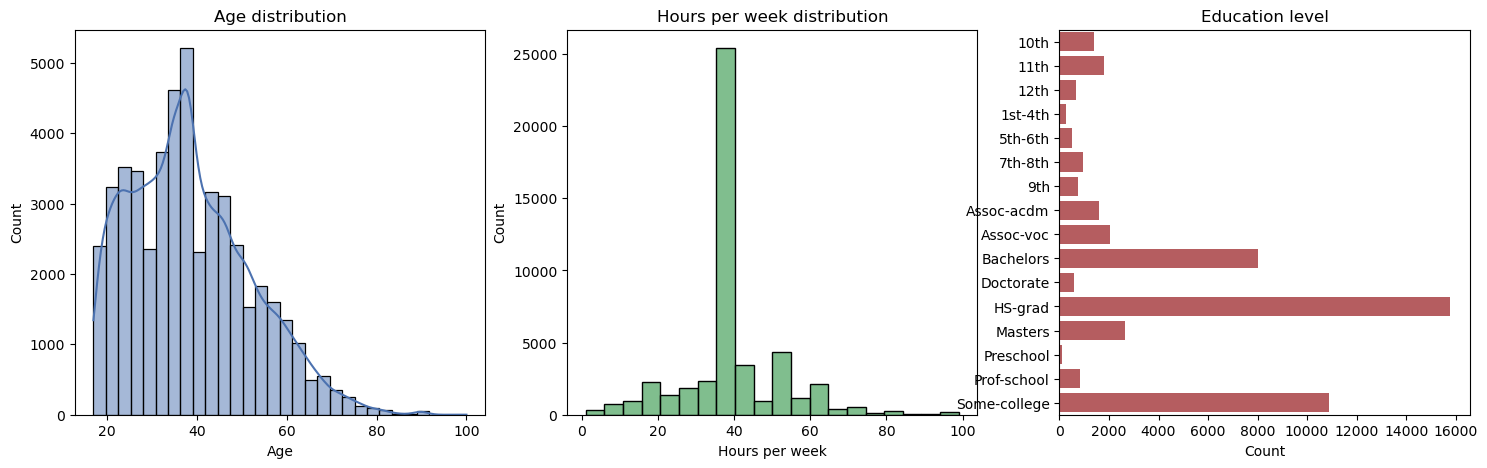

In [102]:
# Data distribution of Age, Hours per week and Education
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df["age"], bins=30, kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("Age distribution")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Count")


sns.histplot(df["hours-per-week"], binwidth=5, ax=axes[1], color="#55A868")
axes[1].set_title("Hours per week distribution")
axes[1].set_xlabel("Hours per week")
axes[1].set_ylabel("Count")

edu = df['education'].unique()
edu.sort()
sns.countplot(data=df, y="education", order=edu, ax=axes[2], color="#C44E52")
axes[2].set_title("Education level")
axes[2].set_xlabel("Count")
axes[2].set_ylabel("")
plt.show()

Correlation

In [103]:
corr = df.corr(numeric_only=True)
corr

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
age,1.000000,-0.074981,0.030313,0.075275,0.056292,0.068129
fnlwgt,-0.074981,1.000000,-0.038681,-0.003702,-0.004359,-0.011251
education-num,0.030313,-0.038681,1.000000,0.125167,0.080977,0.139360
capital-gain,0.075275,-0.003702,0.125167,1.000000,-0.031451,0.081970
capital-loss,0.056292,-0.004359,0.080977,-0.031451,1.000000,0.051069
hours-per-week,0.068129,-0.011251,0.139360,0.081970,0.051069,1.000000


There is no multicoliniarity in the above correlations. Almost all values are near to zero. fnlwgt have a negative coreleation with all other features.

Drawing box plot for checking the outliers

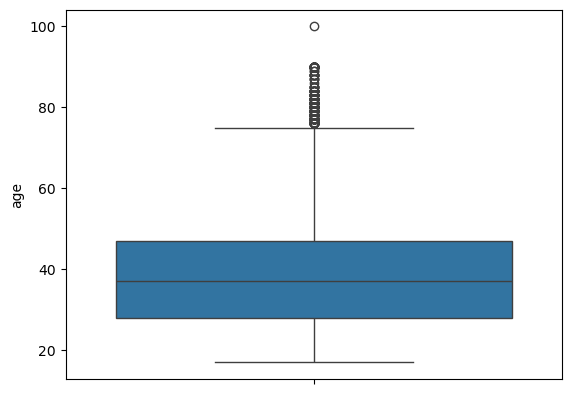

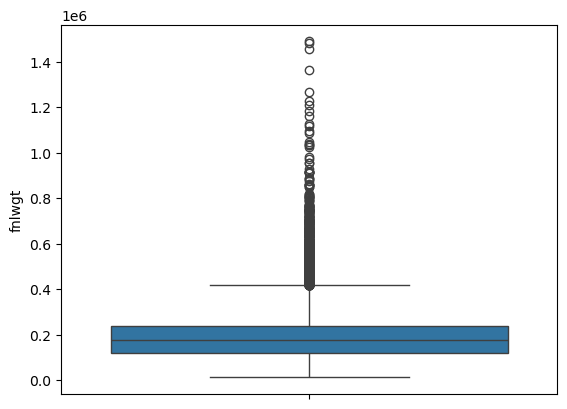

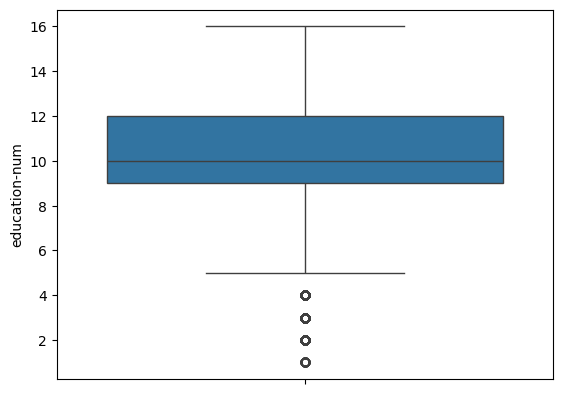

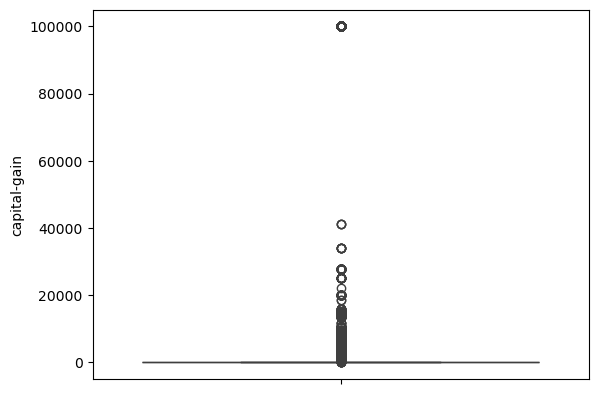

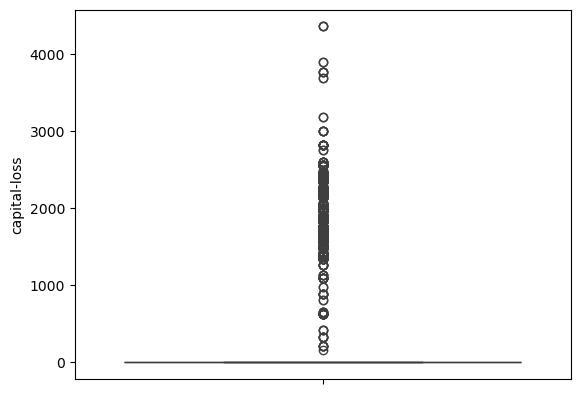

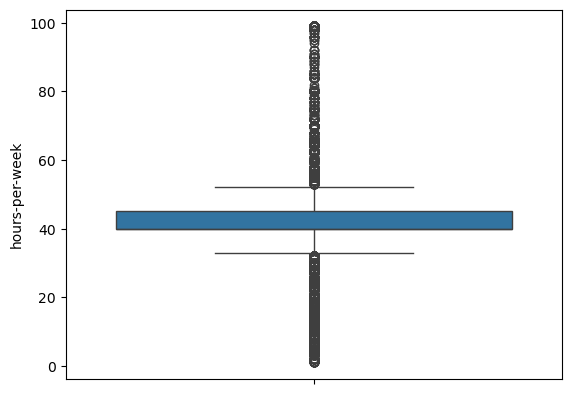

In [104]:
numerical_coumns_df = df.select_dtypes("number")
for i in numerical_coumns_df:
  sns.boxplot(numerical_coumns_df[i])
  plt.show()
#There is outliers in the diagram

Handling Outliers - IQR

In [105]:
def remove_outliers(df, *columns):
    df_filtered = df  # Make a copy of the original DataFrame

    for i in columns:
        Q1 = df[i].quantile(0.25)
        Q3 = df[i].quantile(0.75)
        IQR = Q3 - Q1

        lower_whisker = Q1 - 1.5 * IQR
        upper_whisker = Q3 + 1.5 * IQR

        # Filter out rows where column values are outliers
        df_filtered = df_filtered[(df_filtered[i] >= lower_whisker) & (df_filtered[i] <= upper_whisker)]

    return df_filtered
remove_outliers(df, 'age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week')

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K
5,37.0,Private,284582,Masters,14,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,40.0,United-States,<=50K
7,52.0,Self-emp-not-inc,209642,HS-grad,9,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,45.0,United-States,>50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48835,48.0,Local-gov,349230,Masters,14,Divorced,Other-service,Not-in-family,White,Male,0,0,40.0,United-States,<=50K.
48836,33.0,Private,245211,Bachelors,13,Never-married,Prof-specialty,Own-child,White,Male,0,0,40.0,United-States,<=50K.
48837,39.0,Private,215419,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,36.0,United-States,<=50K.
48838,64.0,Private,321403,HS-grad,9,Widowed,Prof-specialty,Other-relative,Black,Male,0,0,40.0,United-States,<=50K.


# Drawing KDE Plot for skewness

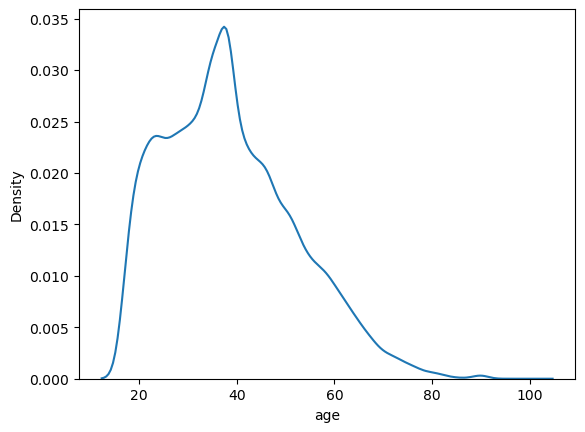

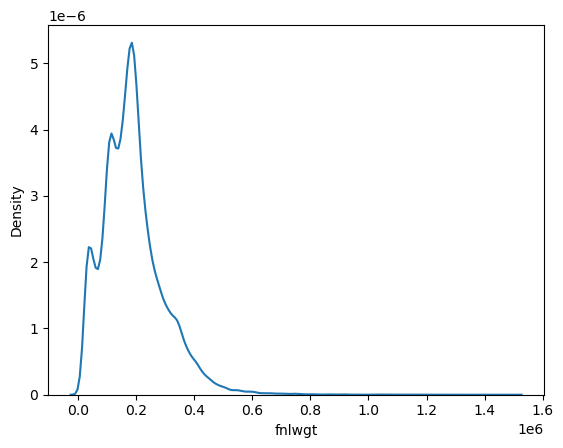

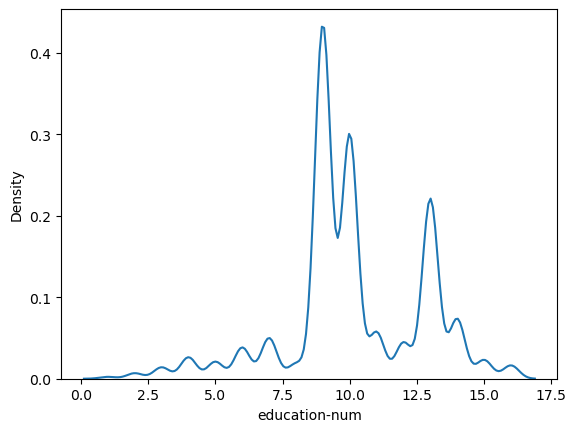

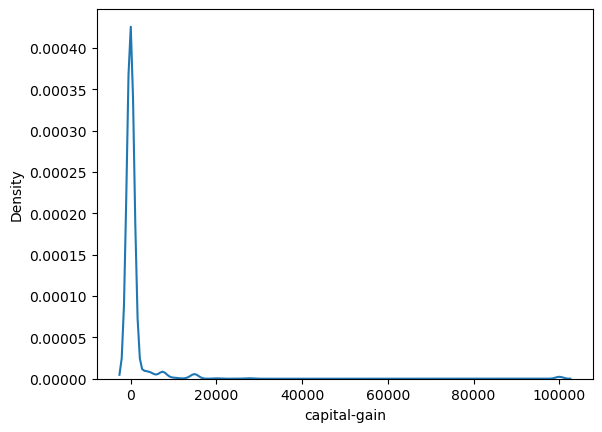

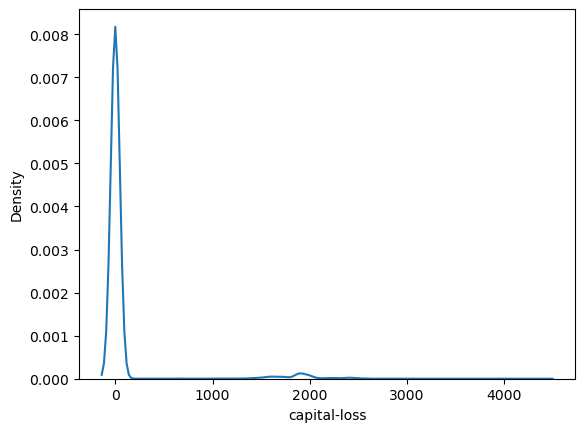

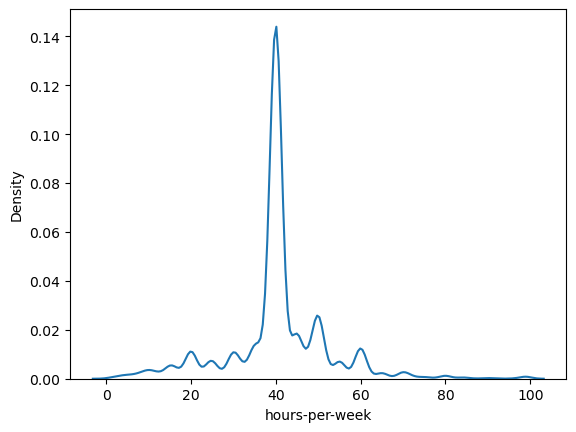

In [106]:
numerical_coumns_df = df.select_dtypes("number")
for i in numerical_coumns_df:
  sns.kdeplot(numerical_coumns_df[i])
  plt.show()

captal gain and capital loss are highly right skewed

Checking skewness values

In [107]:
df.select_dtypes("number").skew().sort_values(ascending=False)

capital-gain      11.892692
capital-loss       4.568956
fnlwgt             1.439357
age                0.589923
hours-per-week     0.246147
education-num     -0.315970
dtype: float64

In [108]:
# Skewness is >2 (Highly skewed) for capital-gain checking three transformations to choose one
df['capital-gain_Log'] = np.log1p(df['capital-gain'])
df['capital-gain_Reciprocal'] = 1 / (df['capital-gain'] + 1e-9)
df['capital-gain_BoxCox'], _ = boxcox(df['capital-gain'] + 1e-9)

print(f"Log: {df['capital-gain_Log'].skew()}")
print(f"Reciprocal: {df['capital-gain_Reciprocal'].skew()}")
print(f"BoxCox: {df['capital-gain_BoxCox'].skew()}")
print(f"capital-gain: {df['capital-gain'].skew()}")

Log: 3.112972019493486
Reciprocal: -3.0317106347291314
BoxCox: 3.031710634767556
capital-gain: 11.892691923804657


In [109]:
#Choosing log transformation
df.drop(["capital-gain_Reciprocal","capital-gain_BoxCox","capital-gain"], axis=1, inplace=True)

In [110]:
# Skewness is >2 (Highly skewed) for capital-loss checking three transformations to choose one
df['capital-loss_Log'] = np.log1p(df['capital-loss'])
df['capital-loss_Reciprocal'] = 1 / (df['capital-loss'] + 1e-9)
df['capital-loss_BoxCox'], _ = boxcox(df['capital-loss'] + 1e-9)

print(f"Log: {df['capital-loss_Log'].skew()}")
print(f"Reciprocal: {df['capital-loss_Reciprocal'].skew()}")
print(f"BoxCox: {df['capital-loss_BoxCox'].skew()}")
print(f"capital-loss: {df['capital-loss'].skew()}")

Log: 4.302144302380041
Reciprocal: -4.2949162962852885
BoxCox: 4.294916296285287
capital-loss: 4.568956145690445


In [111]:
#Choosing log transformation
df.drop(["capital-loss_Reciprocal","capital-loss_BoxCox","capital-loss"], axis=1, inplace=True)

In [112]:
# Skewness is between 1 to 2 (Moderately skewed) for fnlwgt checking three transformations to choose one
df['fnlwgt_Log'] = np.log1p(df['fnlwgt'])
df['fnlwgt_Sqrt'] = np.sqrt(df['fnlwgt'])
df['fnlwgt_CubeRoot'] = np.cbrt(df['fnlwgt'])
print(f"Log: {df['fnlwgt_Log'].skew()}")
print(f"Square Root: {df['fnlwgt_Sqrt'].skew()}")
print(f"Cube Root: {df['fnlwgt_CubeRoot'].skew()}")
print(f"fnlwgt: {df['fnlwgt'].skew()}")

Log: -0.8363373035268202
Square Root: 0.1925052213607548
Cube Root: -0.1592126944536806
fnlwgt: 1.4393574219233822


In [113]:
#Choosing square root transformation
df.drop(["fnlwgt_Log","fnlwgt_CubeRoot","fnlwgt"], axis=1, inplace=True)

** Encoding **

In [114]:
df.select_dtypes('object').nunique()

workclass          8
education         16
marital-status     7
occupation        14
relationship       6
race               5
sex                2
native-country    41
income             4
dtype: int64

sex -> Binary -> Label Encoding
education -> Ordinal -> Ordinal Encoding
workclass, marital-status, race, relationship -> Low cardinality -> One Hot Encoding
native-country, occupation -> High Cardinality -> Frequency Encoding

In [115]:
#Label encoding for sex
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['sex_enc'] = le.fit_transform(df['sex'])
df.drop('sex', axis=1, inplace=True)

In [116]:
#Ordinal encoding with order of education
from sklearn.preprocessing import OrdinalEncoder
oe = OrdinalEncoder(categories=[['Preschool', '1st-4th', '5th-6th', '7th-8th', '9th', '10th', '11th', '12th','HS-grad', 'Some-college', 'Assoc-voc', 'Assoc-acdm','Bachelors', 'Masters', 'Prof-school', 'Doctorate']])
df['education_enc'] = oe.fit_transform(df[['education']])
df.drop('education', axis=1, inplace=True)

In [117]:
# One hot encoding - workclass, marital-status, race, relationship

from sklearn.preprocessing import OneHotEncoder

cat_cols = ["workclass", "marital-status", "race", "relationship"]

ohe = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)
encoded = ohe.fit_transform(df[cat_cols])

encoded_df = pd.DataFrame(
    encoded,
    columns=ohe.get_feature_names_out(cat_cols),
    index=df.index,
)

# Addin the encoded data to df and dropping the original columns
df = pd.concat([df.drop(columns=cat_cols), encoded_df], axis=1)

In [118]:
# Frequency Encoding - native-country
freq_map_country = df["native-country"].value_counts(normalize=True).to_dict()
print(freq_map_country)
df["native-country_Freq_Encoded"] = df["native-country"].map(freq_map_country)
df.drop("native-country",axis=1,inplace=True)

{'United-States': 0.9189571130135583, 'Mexico': 0.018555687543521895, 'Philippines': 0.0057756113546061525, 'Germany': 0.0039732929177077785, 'Puerto-Rico': 0.003584155982468357, 'Canada': 0.003481751525826404, 'El-Salvador': 0.00301069102527342, 'India': 0.0029287674599598576, 'Cuba': 0.0027034776553475606, 'England': 0.0024986687420636548, 'China': 0.0023962642854217014, 'South': 0.002170974480809405, 'Italy': 0.002109531806824233, 'Jamaica': 0.002089050915495842, 'Dominican-Republic': 0.002068570024167452, 'Japan': 0.0017818375455699832, 'Guatemala': 0.0017203948715848114, 'Vietnam': 0.0016999139802564207, 'Poland': 0.0016794330889280302, 'Columbia': 0.0016589521975996396, 'Haiti': 0.0015155859583009053, 'Portugal': 0.0013517388276737803, 'Taiwan': 0.0012493343710318274, 'Iran': 0.0011059681317330931, 'Greece': 0.0009626018924343587, 'Nicaragua': 0.0009421210011059682, 'Peru': 0.0009216401097775775, 'Ecuador': 0.0008806783271207962, 'France': 0.000737312087822062, 'Ireland': 0.00069

In [119]:
# Frequency Encoding - occupation
freq_map_occupation = df["occupation"].value_counts(normalize=True).to_dict()
print(freq_map_occupation)
df["occupation_Freq_Encoded"] = df["occupation"].map(freq_map_occupation)
df.drop("occupation",axis=1,inplace=True)

{'Prof-specialty': 0.22459345430713146, 'Craft-repair': 0.11858436079138164, 'Exec-managerial': 0.11817474296481383, 'Adm-clerical': 0.10912218899766518, 'Sales': 0.10713554253881129, 'Other-service': 0.09531806824232991, 'Machine-op-inspct': 0.05882111989513784, 'Transport-moving': 0.04583623479293819, 'Handlers-cleaners': 0.04047024126489985, 'Farming-fishing': 0.029246712816941793, 'Tech-support': 0.028304591815835826, 'Protective-serv': 0.019313480522672347, 'Priv-house-serv': 0.004772047679515013, 'Armed-Forces': 0.0003072133699258592}


Scaling

Numerical columns : capital-gain_Log, capital-loss_Log, fnlwgt_Sqrt, age, hours-per-week, education-num 
Standard Scaling is applying for these columns

In [120]:
from sklearn.preprocessing import StandardScaler
scale_columns = ['capital-gain_Log', 'capital-loss_Log', 'fnlwgt_Sqrt', 'age', 'hours-per-week', 'education-num']
scaler = StandardScaler()
df[scale_columns] = scaler.fit_transform(df[scale_columns])
df.head(3)

,age,education-num,hours-per-week,income,capital-gain_Log,capital-loss_Log,fnlwgt_Sqrt,sex_enc,education_enc,workclass_Local-gov,...,race_Black,race_Other,race_White,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,native-country_Freq_Encoded,occupation_Freq_Encoded
0,0.032481,1.136533,-0.032546,<=50K,2.844037,-0.221302,-1.171936,1,12.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.918957,0.109122
1,0.854354,1.136533,-2.269439,<=50K,-0.297971,-0.221302,-1.086574,1,12.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.918957,0.118175
2,-0.042235,-0.419444,-0.032546,<=50K,-0.297971,-0.221302,0.381353,1,8.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.918957,0.040470


Dropping income column

In [121]:
df.drop('income',axis=1,inplace=True)

Elbow Method

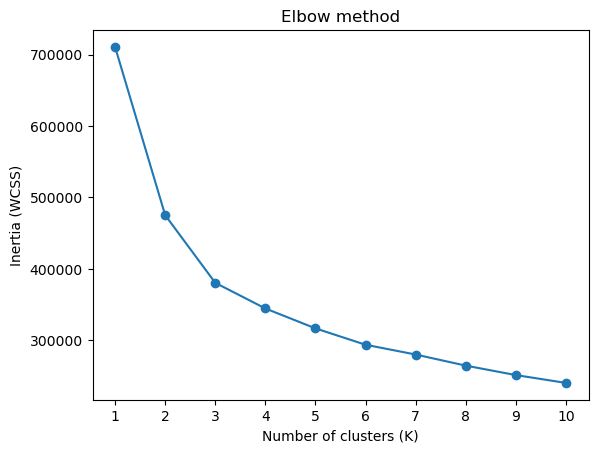

In [122]:
from sklearn.cluster import KMeans,DBSCAN,AgglomerativeClustering
inertias = []
k_range = range(1, 11)
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(df)
    inertias.append(km.inertia_)

# 3. Plot
plt.plot(k_range, inertias, marker="o")
plt.xticks(k_range)
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow method")
plt.show()

Choosing k = 3 from above diagram

In [123]:
from sklearn.cluster import KMeans,DBSCAN,AgglomerativeClustering  #knn, dt, rf
kmeans = KMeans(n_clusters=3,init="k-means++",n_init=15, max_iter=300)  # Example with 3 clusters
df['Cluster'] = kmeans.fit_predict(df)
df

,age,education-num,hours-per-week,capital-gain_Log,capital-loss_Log,fnlwgt_Sqrt,sex_enc,education_enc,workclass_Local-gov,workclass_Never-worked,...,race_Other,race_White,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,native-country_Freq_Encoded,occupation_Freq_Encoded,Cluster
0,0.032481,1.136533,-0.032546,2.844037,-0.221302,-1.171936,1,12.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.918957,0.109122,2
1,0.854354,1.136533,-2.269439,-0.297971,-0.221302,-1.086574,1,12.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.918957,0.118175,2
2,-0.042235,-0.419444,-0.032546,-0.297971,-0.221302,0.381353,1,8.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.918957,0.040470,0
3,1.078501,-1.197432,-0.032546,-0.297971,-0.221302,0.549271,1,6.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.918957,0.040470,1
4,-0.789392,1.136533,-0.032546,-0.297971,-0.221302,1.361575,0,12.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.002703,0.224593,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,0.032481,1.136533,-0.363938,-0.297971,-0.221302,0.379311,0,12.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.918957,0.224593,2
48838,1.900373,-0.419444,-0.032546,-0.297971,-0.221302,1.237910,1,8.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.918957,0.224593,0
48839,-0.042235,1.136533,0.795933,-0.297971,-0.221302,1.617415,1,12.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.918957,0.224593,2
48840,0.406059,1.136533,-0.032546,3.220061,-0.221302,-1.078197,1,12.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.918957,0.109122,2


In [124]:
# Silhoutte Score
from sklearn.metrics import silhouette_score
labels = kmeans.labels_
silhouette_avg = silhouette_score(df, labels)

print(silhouette_avg)

0.34100493489214684


Silhouette score of 0.34 means a weak structure of clusters

In [125]:
df.drop('Cluster',axis=1,inplace=True)

Agglomerative Clustering

In [126]:
from sklearn.cluster import KMeans, AgglomerativeClustering 

# Example with 3 clusters
hc = AgglomerativeClustering(n_clusters=3,linkage="single")

# Fit and predict clusters
df['Cluster'] = hc.fit_predict(df)

df.head()

,age,education-num,hours-per-week,capital-gain_Log,capital-loss_Log,fnlwgt_Sqrt,sex_enc,education_enc,workclass_Local-gov,workclass_Never-worked,...,race_Other,race_White,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,native-country_Freq_Encoded,occupation_Freq_Encoded,Cluster
0,0.032481,1.136533,-0.032546,2.844037,-0.221302,-1.171936,1,12.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.918957,0.109122,0
1,0.854354,1.136533,-2.269439,-0.297971,-0.221302,-1.086574,1,12.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.918957,0.118175,0
2,-0.042235,-0.419444,-0.032546,-0.297971,-0.221302,0.381353,1,8.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.918957,0.040470,0
3,1.078501,-1.197432,-0.032546,-0.297971,-0.221302,0.549271,1,6.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.918957,0.040470,0
4,-0.789392,1.136533,-0.032546,-0.297971,-0.221302,1.361575,0,12.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.002703,0.224593,0


In [127]:
from sklearn.metrics import silhouette_score
labels = hc.labels_
silhouette_avg = silhouette_score(df, labels)

print(silhouette_avg)

0.2968433470342886


In [128]:
cluster_summary = df.groupby("Cluster").agg({
    "age": ["mean"],
    "education-num": ["mean"],
    "hours-per-week": ["mean"],
    "education_enc": ["mean"]
})

cluster_summary

,age,education-num,hours-per-week,education_enc
,mean,mean,mean,mean
Cluster,,,,
0,-0.011270,-0.017161,-0.010645,9.034162
1,0.229518,0.350703,0.214981,9.979842
2,0.779638,-1.586426,4.855479,5.000000


In [129]:
df.drop('Cluster',axis=1,inplace=True)

DBSCAN


In [130]:
# DBSCAN
from sklearn.cluster import DBSCAN



db = DBSCAN(eps=1 ,min_samples=8)
labels = db.fit_predict(df) 


df['cluster'] = labels
df['cluster'].value_counts()

cluster
-1      15906
 12      3652
 15      1910
 18      1658
 0       1156
        ...  
 288        8
 311        8
 337        7
 314        6
 329        4
Name: count, Length: 339, dtype: int64

In [131]:
from sklearn.metrics import silhouette_score
labels = db.labels_
silhouette_avg = silhouette_score(df, labels)

print(silhouette_avg)

0.22496451746225185
